# TerraMesh-Masks playground

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from torch.utils.data import DataLoader
from terramesh.masks_dataset import build_terramesh_masks_dataset

## Load and visualize some samples

In [2]:
TAR_PATH = Path("https://huggingface.co/datasets/ibm-esa-geospatial/TerraMesh-Masks/resolve/main/val/[BINARY_MASK,S2RGB]/majortom_shard_000001.tar")
dataset = build_terramesh_masks_dataset(
    str(TAR_PATH),
    batch_size=4,
    shardshuffle=10,
    empty_check=False,
    return_metadata=False,
    transform=None,
    partial=True,
    filter_set=set(),
    whitelist_mask_uid=set(),
)
dataloader  = DataLoader(dataset, batch_size=None)
first_batch = next(iter(dataloader))
print(first_batch.keys())

dict_keys(['BINARY_MASK', 'S2RGB', '__key__', 'annotation'])


In [3]:
# Print shapes of modalities in the first batch
print("Batch shapes:")
print(f"BINARY_MASK: {first_batch['BINARY_MASK'].shape}")

Batch shapes:
BINARY_MASK: torch.Size([4, 264, 264])


In [5]:
first_batch['annotation']['class_label']

['vegetated island', 'tropical forest', 'wetland', 'wetland']

## Visualizing binary masks with RGB

In [6]:
def plot_sample(rgb, anno, label=None, ax=None):
    if ax is None:
        fig, ax = plt.subplots(figsize=(3,3))
    ax.imshow(rgb.permute(1,2,0))
    anno[:, -1] = anno[:, 0] = anno[-1] = anno[0] = 0  # Set boarder to 0 for plotting contour.

    # overlay mask in red
    ax.imshow(anno, cmap='Reds', vmin=0, vmax=1, alpha=0.3)
    ax.contour(anno, levels=[0.5], colors='red', linewidths=1.5)
    # ax.axis("off") # Keep
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.spines["bottom"].set_visible(False)
    ax.spines["left"].set_visible(False)
    ax.set_yticks([])
    ax.set_xticks([])
    ax.set_title(label.capitalize())

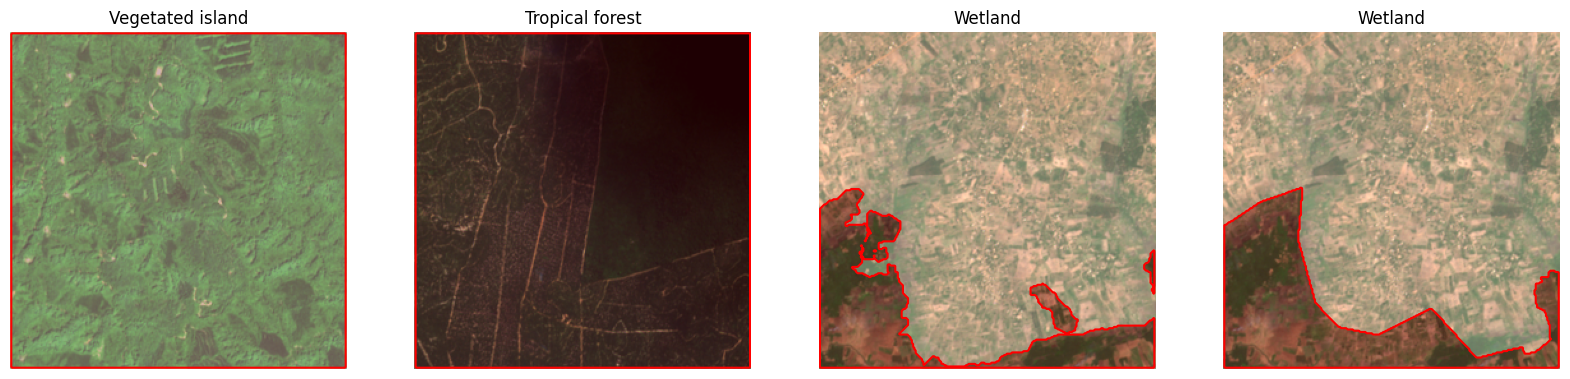

In [7]:
fig, ax = plt.subplots(ncols=4, figsize=(20, 5))
for i in range(4):
    plot_sample(first_batch["S2RGB"][i], first_batch["BINARY_MASK"][i], label=first_batch['annotation']['class_label'][i], ax=ax[i])
plt.show()

## Using metadata parquet file

The associated metadata can be used to filter the data for various needs. 


In [7]:
# Download from https://huggingface.co/datasets/ibm-esa-geospatial/TerraMesh-Masks/resolve/main/val_metadata.parquet
METADATA_PATH = Path("data/TerraMesh/val_metadata.parquet")

metadata_df = pd.read_parquet(METADATA_PATH)

In [8]:
# Example : get all the samples with ndvi_agreement > 0.4
whitelist_uids = set(metadata_df[metadata_df["ndvi_agreement"] > 0.4]["mask_uid"])
print(f"Generated whitelist of {len(whitelist_uids)} UIDs with ndvi_agreement > 0.4")

Generated whitelist of 122741 UIDs with ndvi_agreement > 0.4


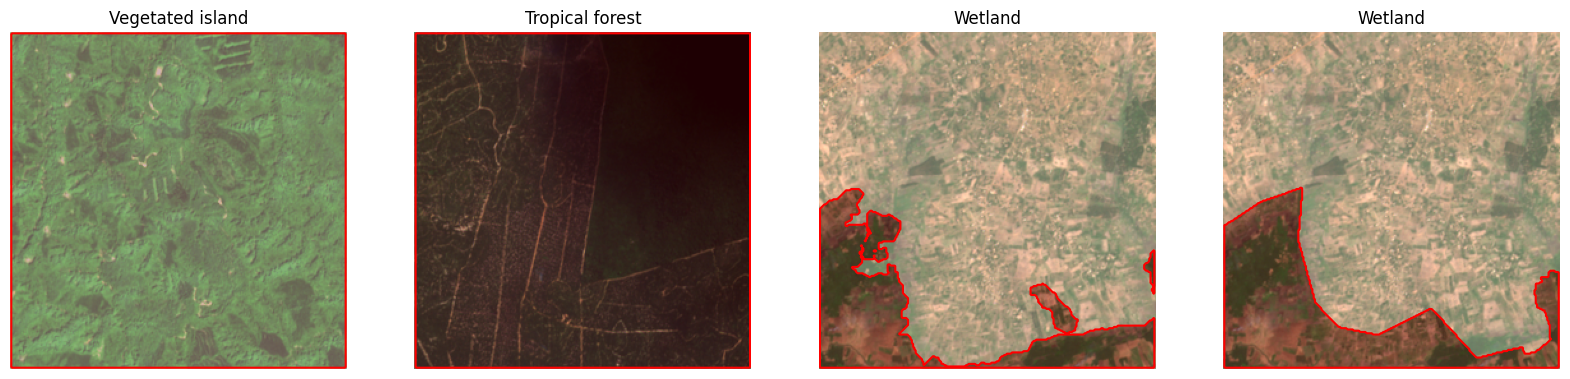

In [9]:
dataset = build_terramesh_masks_dataset(
    str(TAR_PATH),
    batch_size=4,
    shardshuffle=10,
    seed=42,
    empty_check=False,
    return_metadata=False,
    transform=None,
    partial=True,
    filter_set=set(),
    whitelist_mask_uid=whitelist_uids,
)
first_batch = next(iter(dataset))

fig, ax = plt.subplots(ncols=4, figsize=(20, 5))
for i in range(4):
    plot_sample(first_batch["S2RGB"][i], first_batch["BINARY_MASK"][i], label=first_batch['annotation']['class_label'][i], ax=ax[i])
plt.show()

In [10]:
# Example: Filter only samples with class label containing "airport"
class_mask = metadata_df["class_label"].fillna("").str.contains("residential", case=False, regex=False)
whitelist_uids = set(metadata_df.loc[class_mask, "mask_uid"])
print(f"Generated whitelist of {len(whitelist_uids)} UIDs with class_label containing 'residential'")

Generated whitelist of 6123 UIDs with class_label containing 'residential'


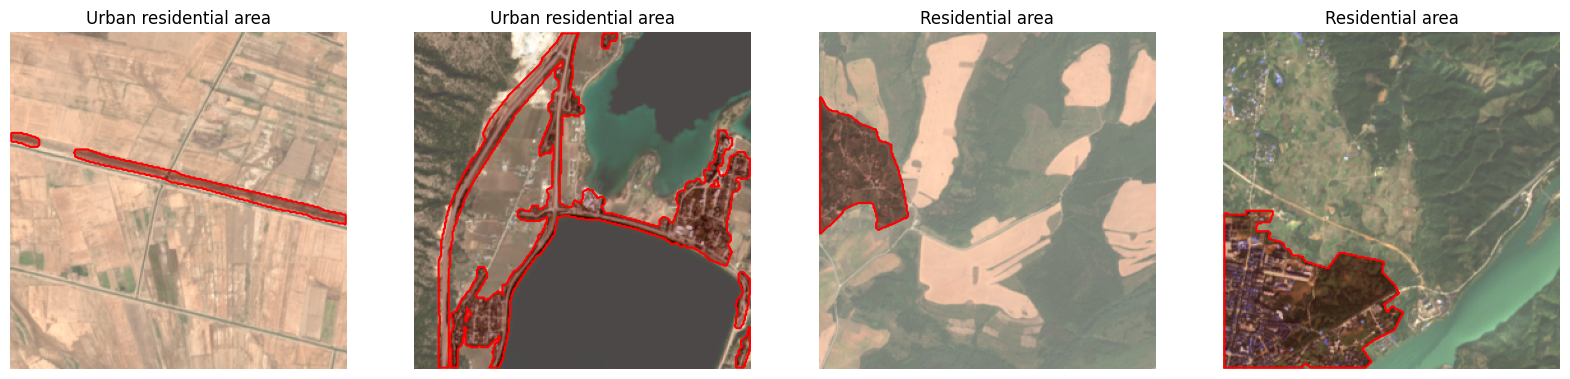

In [11]:
dataset = build_terramesh_masks_dataset(
    str(TAR_PATH),
    batch_size=4,
    shardshuffle=0,
    empty_check=False,
    return_metadata=False,
    transform=None,
    time_dim=True,
    partial=True,
    filter_set=set(),
    whitelist_mask_uid=whitelist_uids,
)
first_batch = next(iter(dataset))

fig, ax = plt.subplots(ncols=4, figsize=(20, 5))
for i in range(4):
    plot_sample(first_batch["S2RGB"][i], first_batch["BINARY_MASK"][i], label=first_batch['annotation']['class_label'][i], ax=ax[i])
plt.show()